# Traffic Sign Detection Using Convolutional Neural Network (CNN)

## Project Title
**Traffic Sign Detection Using Deep Learning**

### Project ID
**PRAICP-1002-TrafSignDetc**

### Project Overview
This project develops an image-classification model for recognizing traffic signs from images. The workflow includes dataset inspection, image preprocessing, exploratory data analysis, visualization of traffic-sign attributes, train/validation splitting, CNN model development, image augmentation, model training, evaluation, prediction, confusion-matrix analysis, classification-report analysis, and model saving.

The project specification states that the main goals are image preprocessing and building a machine-learning model to predict the traffic sign.

> **Important notebook note:** The CSV metadata reports 39,209 training records and 12,630 test records, while the notebook's folder-based loading step actually loads 2,430 training images. The CNN is therefore trained on the 2,430 images loaded from the training folders. This distinction should be mentioned in the project report rather than presenting 39,209 as the number actually used for CNN training.

## 1. Abstract

Traffic sign recognition is an important computer-vision task for intelligent transportation and driver-assistance systems. This project uses a Convolutional Neural Network (CNN) to classify traffic-sign images into 43 classes. The images are resized to 32×32 pixels and normalized to the range 0–1. The training pipeline uses data augmentation, batch normalization, dropout, early stopping, and learning-rate reduction to improve training behavior.

The notebook also evaluates the trained model using accuracy, loss, top-3 accuracy, top-5 accuracy, confusion matrix, and a classification report. The final saved model is stored in Keras format for later reuse.

## 2. Introduction

Traffic signs communicate rules, warnings, restrictions, and directions to road users. Automatic traffic-sign recognition can help computer-vision systems interpret road environments.

In this project, a supervised deep-learning approach is used. Each input image is associated with a traffic-sign class, and the CNN learns visual patterns such as edges, shapes, colors, and increasingly complex features through convolutional layers.

The project specification describes a directory-based image dataset containing different traffic signs.

## 3. Problem Statement

Build an image-classification system that takes a traffic-sign image as input and predicts its corresponding traffic-sign class.

### Main Goals
1. Perform image preprocessing.
2. Develop a machine-learning/deep-learning model to predict traffic signs.
3. Evaluate the trained model using quantitative and visual metrics.
4. Save the trained model so it can be loaded and reused.

## 4. Project Objectives

- Inspect and understand the traffic-sign dataset.
- Explore class, shape, and color distributions.
- Resize images to a consistent 32×32×3 format.
- Normalize pixel values.
- Split the available training images into training and validation sets.
- Build a multi-class CNN classifier with 43 output classes.
- Apply image augmentation to the training data.
- Use callbacks to control overfitting and learning rate.
- Evaluate the model on the test dataset.
- Analyze errors using a confusion matrix and classification report.
- Save the trained model in `.keras` format.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##  Libraries and Environment

The notebook uses Google Colab with Python and the following main libraries:

- **NumPy** – numerical arrays and preprocessing
- **Pandas** – tabular dataset inspection
- **OpenCV (cv2)** – image loading and color conversion
- **Pillow (PIL)** – image resizing/loading
- **Matplotlib / Seaborn** – visualization
- **Scikit-learn** – train/validation splitting and evaluation metrics
- **TensorFlow / Keras** – CNN construction, training, and model saving

In [ ]:
import os, glob
import tqdm
import cv2
from PIL import Image

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout


In [ ]:
import os

project_path = "/content/drive/MyDrive/traffic signal project"

print(os.listdir(project_path))

['Meta.csv', 'Test.csv', 'Train.csv', 'Meta', 'Train', 'Test']


In [ ]:
import pandas as pd

data_path = '/content/drive/MyDrive/traffic signal project/'

train_path = data_path + 'Train/'
test_path = data_path + 'Test/'

df_meta = pd.read_csv(data_path + 'Meta.csv')
df_train = pd.read_csv(data_path + 'Train.csv')
df_test = pd.read_csv(data_path + 'Test.csv')

print("Meta shape:", df_meta.shape)
print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)

Meta shape: (43, 5)
Train shape: (39209, 8)
Test shape: (12630, 8)


In [ ]:


meta_folder = data_path + 'Meta'

num_meta_images = len([
    f for f in os.listdir(meta_folder)
    if os.path.isfile(os.path.join(meta_folder, f))
    and f.lower().endswith('.png')
])

print(f"Number of images in Meta folder: {num_meta_images}")

Number of images in Meta folder: 43


##  Dataset Description

The project contains metadata and image data organized around traffic-sign classes. The notebook reads:

- `Meta.csv`
- `Train.csv`
- `Test.csv`
- `Meta/`
- `Train/`
- `Test/`

The metadata contains 43 traffic-sign classes. The notebook maps the class IDs to descriptive names such as speed limits, no-passing signs, stop, yield, traffic signals, pedestrian crossing, road work, roundabout, and other traffic signs.

### Dataset information observed in the notebook
- Metadata shape: **43 × 5**
- Training CSV shape: **39,209 × 8**
- Test CSV shape: **12,630 × 8**
- Test images actually loaded by the notebook: **12,630**
- Training images actually loaded from folders: **2,430**
- CNN classes: **43**

In [ ]:
df_meta.head(10)

,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22
5,Meta/12.png,12,2,2,2.3
6,Meta/13.png,13,4,0,2.1
7,Meta/14.png,14,3,0,2.2
8,Meta/15.png,15,1,0,3.1
9,Meta/16.png,16,1,0,3.3


In [ ]:
df_meta.index

RangeIndex(start=0, stop=43, step=1)

In [ ]:
df_meta.columns

Index(['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId'], dtype='object')

In [ ]:
df_meta.shape

(43, 5)

In [ ]:
df_meta.describe()

,ClassId,ShapeId,ColorId
count,43.000000,43.000000,43.000000
mean,21.000000,0.790698,0.511628
std,12.556539,0.803508,0.935340
min,0.000000,0.000000,0.000000
25%,10.500000,0.000000,0.000000
50%,21.000000,1.000000,0.000000
75%,31.500000,1.000000,1.000000
max,42.000000,4.000000,3.000000


In [ ]:
df_meta.duplicated().sum()

np.int64(0)

In [ ]:
print("Min ClassId value    : {}".format(df_meta.ClassId.min()))
print("Max ClassId value    : {}".format(df_meta.ClassId.max()))
print("Total ClassID values : {}".format(len(df_meta.ClassId.unique())))

Min ClassId value    : 0
Max ClassId value    : 42
Total ClassID values : 43


In [ ]:
train_folder = data_path + 'Train'

class_folders = [folder for folder in os.listdir(train_folder) if os.path.isdir(os.path.join(train_folder, folder))]
total_images = sum(
    len([f for f in os.listdir(os.path.join(train_folder, folder)) if os.path.isfile(os.path.join(train_folder, folder, f))])
    for folder in class_folders
)

print(f"Total number of class folders: {len(class_folders)}")
print(f"Total number of images in Train folder: {total_images}")

Total number of class folders: 2
Total number of images in Train folder: 2430


In [ ]:
df_train.head(10)

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png
5,31,27,6,5,26,22,20,Train/20/00020_00000_00005.png
6,31,28,6,6,26,23,20,Train/20/00020_00000_00006.png
7,31,28,6,6,26,23,20,Train/20/00020_00000_00007.png
8,31,29,5,6,26,24,20,Train/20/00020_00000_00008.png
9,34,32,6,6,29,26,20,Train/20/00020_00000_00009.png


In [ ]:
df_train.index

RangeIndex(start=0, stop=39209, step=1)

In [ ]:
df_train.columns

Index(['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId',
       'Path'],
      dtype='object')

In [ ]:
df_train.shape

(39209, 8)

In [ ]:
df_train.describe()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId
count,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000,39209.000000
mean,50.835880,50.328930,5.999515,5.962381,45.197302,44.728379,15.788390
std,24.306933,23.115423,1.475493,1.385440,23.060157,21.971145,12.013238
min,25.000000,25.000000,0.000000,5.000000,20.000000,20.000000,0.000000
25%,35.000000,35.000000,5.000000,5.000000,29.000000,30.000000,5.000000
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000
75%,58.000000,58.000000,6.000000,6.000000,53.000000,52.000000,25.000000
max,243.000000,225.000000,20.000000,20.000000,223.000000,205.000000,42.000000


In [ ]:
df_train.duplicated().sum()

np.int64(0)

In [ ]:
print("Min ClassId value    : {}".format(df_train.ClassId.min()))
print("Max ClassId value    : {}".format(df_train.ClassId.max()))
print("Total ClassID values : {}".format(len(df_train.ClassId.unique())))

Min ClassId value    : 0
Max ClassId value    : 42
Total ClassID values : 43


In [ ]:
train_counts = df_train.ClassId.value_counts()
train_dict = dict(sorted(train_counts.items()))
train_dict

{0: 210,
 1: 2220,
 2: 2250,
 3: 1410,
 4: 1980,
 5: 1860,
 6: 420,
 7: 1440,
 8: 1410,
 9: 1470,
 10: 2010,
 11: 1320,
 12: 2100,
 13: 2160,
 14: 780,
 15: 630,
 16: 420,
 17: 1110,
 18: 1200,
 19: 210,
 20: 360,
 21: 330,
 22: 390,
 23: 510,
 24: 270,
 25: 1500,
 26: 600,
 27: 240,
 28: 540,
 29: 270,
 30: 450,
 31: 780,
 32: 240,
 33: 689,
 34: 420,
 35: 1200,
 36: 390,
 37: 210,
 38: 2070,
 39: 300,
 40: 360,
 41: 240,
 42: 240}

In [ ]:
# test

In [ ]:
test_folder = data_path + 'Test'

num_test_images = len([
    f for f in os.listdir(test_folder)
    if os.path.isfile(os.path.join(test_folder, f)) and f.lower().endswith('.png')
])

print(f"Number of images in Test folder: {num_test_images}")

Number of images in Test folder: 12633


In [ ]:
df_test.head(10)

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png
5,52,56,5,5,47,51,38,Test/00005.png
6,147,130,12,12,135,119,18,Test/00006.png
7,32,33,5,5,26,28,12,Test/00007.png
8,45,50,6,5,40,45,25,Test/00008.png
9,81,86,7,7,74,79,35,Test/00009.png


In [ ]:
df_test.index

RangeIndex(start=0, stop=12630, step=1)

In [ ]:
df_test.columns

Index(['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId',
       'Path'],
      dtype='object')

In [ ]:
df_test.shape

(12630, 8)

In [ ]:
df_test.describe()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId
count,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000,12630.000000
mean,50.507759,50.364450,5.998021,5.982423,44.864450,44.758116,15.551069
std,25.088483,23.698908,1.543954,1.427424,23.776102,22.494697,11.947123
min,25.000000,25.000000,1.000000,5.000000,20.000000,20.000000,0.000000
25%,34.000000,35.000000,5.000000,5.000000,29.000000,29.000000,5.000000
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000
75%,58.000000,57.000000,6.000000,6.000000,53.000000,52.000000,25.000000
max,266.000000,232.000000,23.000000,19.000000,244.000000,212.000000,42.000000


In [ ]:
df_test.duplicated().sum()

np.int64(0)

In [ ]:
print("Min ClassId value    : {}".format(df_test.ClassId.min()))
print("Max ClassId value    : {}".format(df_test.ClassId.max()))
print("Total ClassID values : {}".format(len(df_test.ClassId.unique())))

Min ClassId value    : 0
Max ClassId value    : 42
Total ClassID values : 43


In [ ]:
test_counts = df_test.ClassId.value_counts()
test_dict = dict(sorted(test_counts.items()))
test_dict

{0: 60,
 1: 720,
 2: 750,
 3: 450,
 4: 660,
 5: 630,
 6: 150,
 7: 450,
 8: 450,
 9: 480,
 10: 660,
 11: 420,
 12: 690,
 13: 720,
 14: 270,
 15: 210,
 16: 150,
 17: 360,
 18: 390,
 19: 60,
 20: 90,
 21: 90,
 22: 120,
 23: 150,
 24: 90,
 25: 480,
 26: 180,
 27: 60,
 28: 150,
 29: 90,
 30: 150,
 31: 270,
 32: 60,
 33: 210,
 34: 120,
 35: 390,
 36: 120,
 37: 60,
 38: 690,
 39: 90,
 40: 90,
 41: 60,
 42: 90}

In [ ]:
# Mapping Class IDs to Traffic Sign Descriptions
num_classes = len(df_meta.ClassId.unique())
class_dict = {}
class_labels = list(range(num_classes))
# Speed Class 0-9
speed_class = ['Speed Limit ' + item for item in [speed + ' kmph' for speed in ['20', '30', '50', '60', '70', '80']]]\
            + ['End of Speed Limit 80 kmph']
speed_class+= ['Speed Limit ' + item for item in [speed + ' kmph' for speed in ['100', '120']]]
speed_class
# 10, 11 No Passing
no_pass = ['No Passing' + item for item in ['', ' vehicle over 3.5 ton']]
# 12-43
rest = ['Right-of-way at intersection', 'Priority road', 'Yield', 'Stop', 'No vehicles', 'Veh > 3.5 tons prohibited',\
            'No entry', 'General caution', 'Dangerous curve left', 'Dangerous curve right', 'Double curve', 'Bumpy road',
            'Slippery road', 'Road narrows on the right', 'Road work', 'Traffic signals', 'Pedestrians', 'Children crossing',
            'Bicycles crossing', 'Beware of ice/snow','Wild animals crossing', 'End speed + passing limits', 'Turn right ahead',
            'Turn left ahead', 'Ahead only', 'Go straight or right', 'Go straight or left', 'Keep right', 'Keep left',
            'Roundabout mandatory', 'End of no passing', 'End no passing vehicle > 3.5 tons']
class_values = speed_class + no_pass + rest
class_dict = {keys:values for keys,values in zip(class_labels, class_values)}
class_dict

{0: 'Speed Limit 20 kmph',
 1: 'Speed Limit 30 kmph',
 2: 'Speed Limit 50 kmph',
 3: 'Speed Limit 60 kmph',
 4: 'Speed Limit 70 kmph',
 5: 'Speed Limit 80 kmph',
 6: 'End of Speed Limit 80 kmph',
 7: 'Speed Limit 100 kmph',
 8: 'Speed Limit 120 kmph',
 9: 'No Passing',
 10: 'No Passing vehicle over 3.5 ton',
 11: 'Right-of-way at intersection',
 12: 'Priority road',
 13: 'Yield',
 14: 'Stop',
 15: 'No vehicles',
 16: 'Veh > 3.5 tons prohibited',
 17: 'No entry',
 18: 'General caution',
 19: 'Dangerous curve left',
 20: 'Dangerous curve right',
 21: 'Double curve',
 22: 'Bumpy road',
 23: 'Slippery road',
 24: 'Road narrows on the right',
 25: 'Road work',
 26: 'Traffic signals',
 27: 'Pedestrians',
 28: 'Children crossing',
 29: 'Bicycles crossing',
 30: 'Beware of ice/snow',
 31: 'Wild animals crossing',
 32: 'End speed + passing limits',
 33: 'Turn right ahead',
 34: 'Turn left ahead',
 35: 'Ahead only',
 36: 'Go straight or right',
 37: 'Go straight or left',
 38: 'Keep right',
 39:

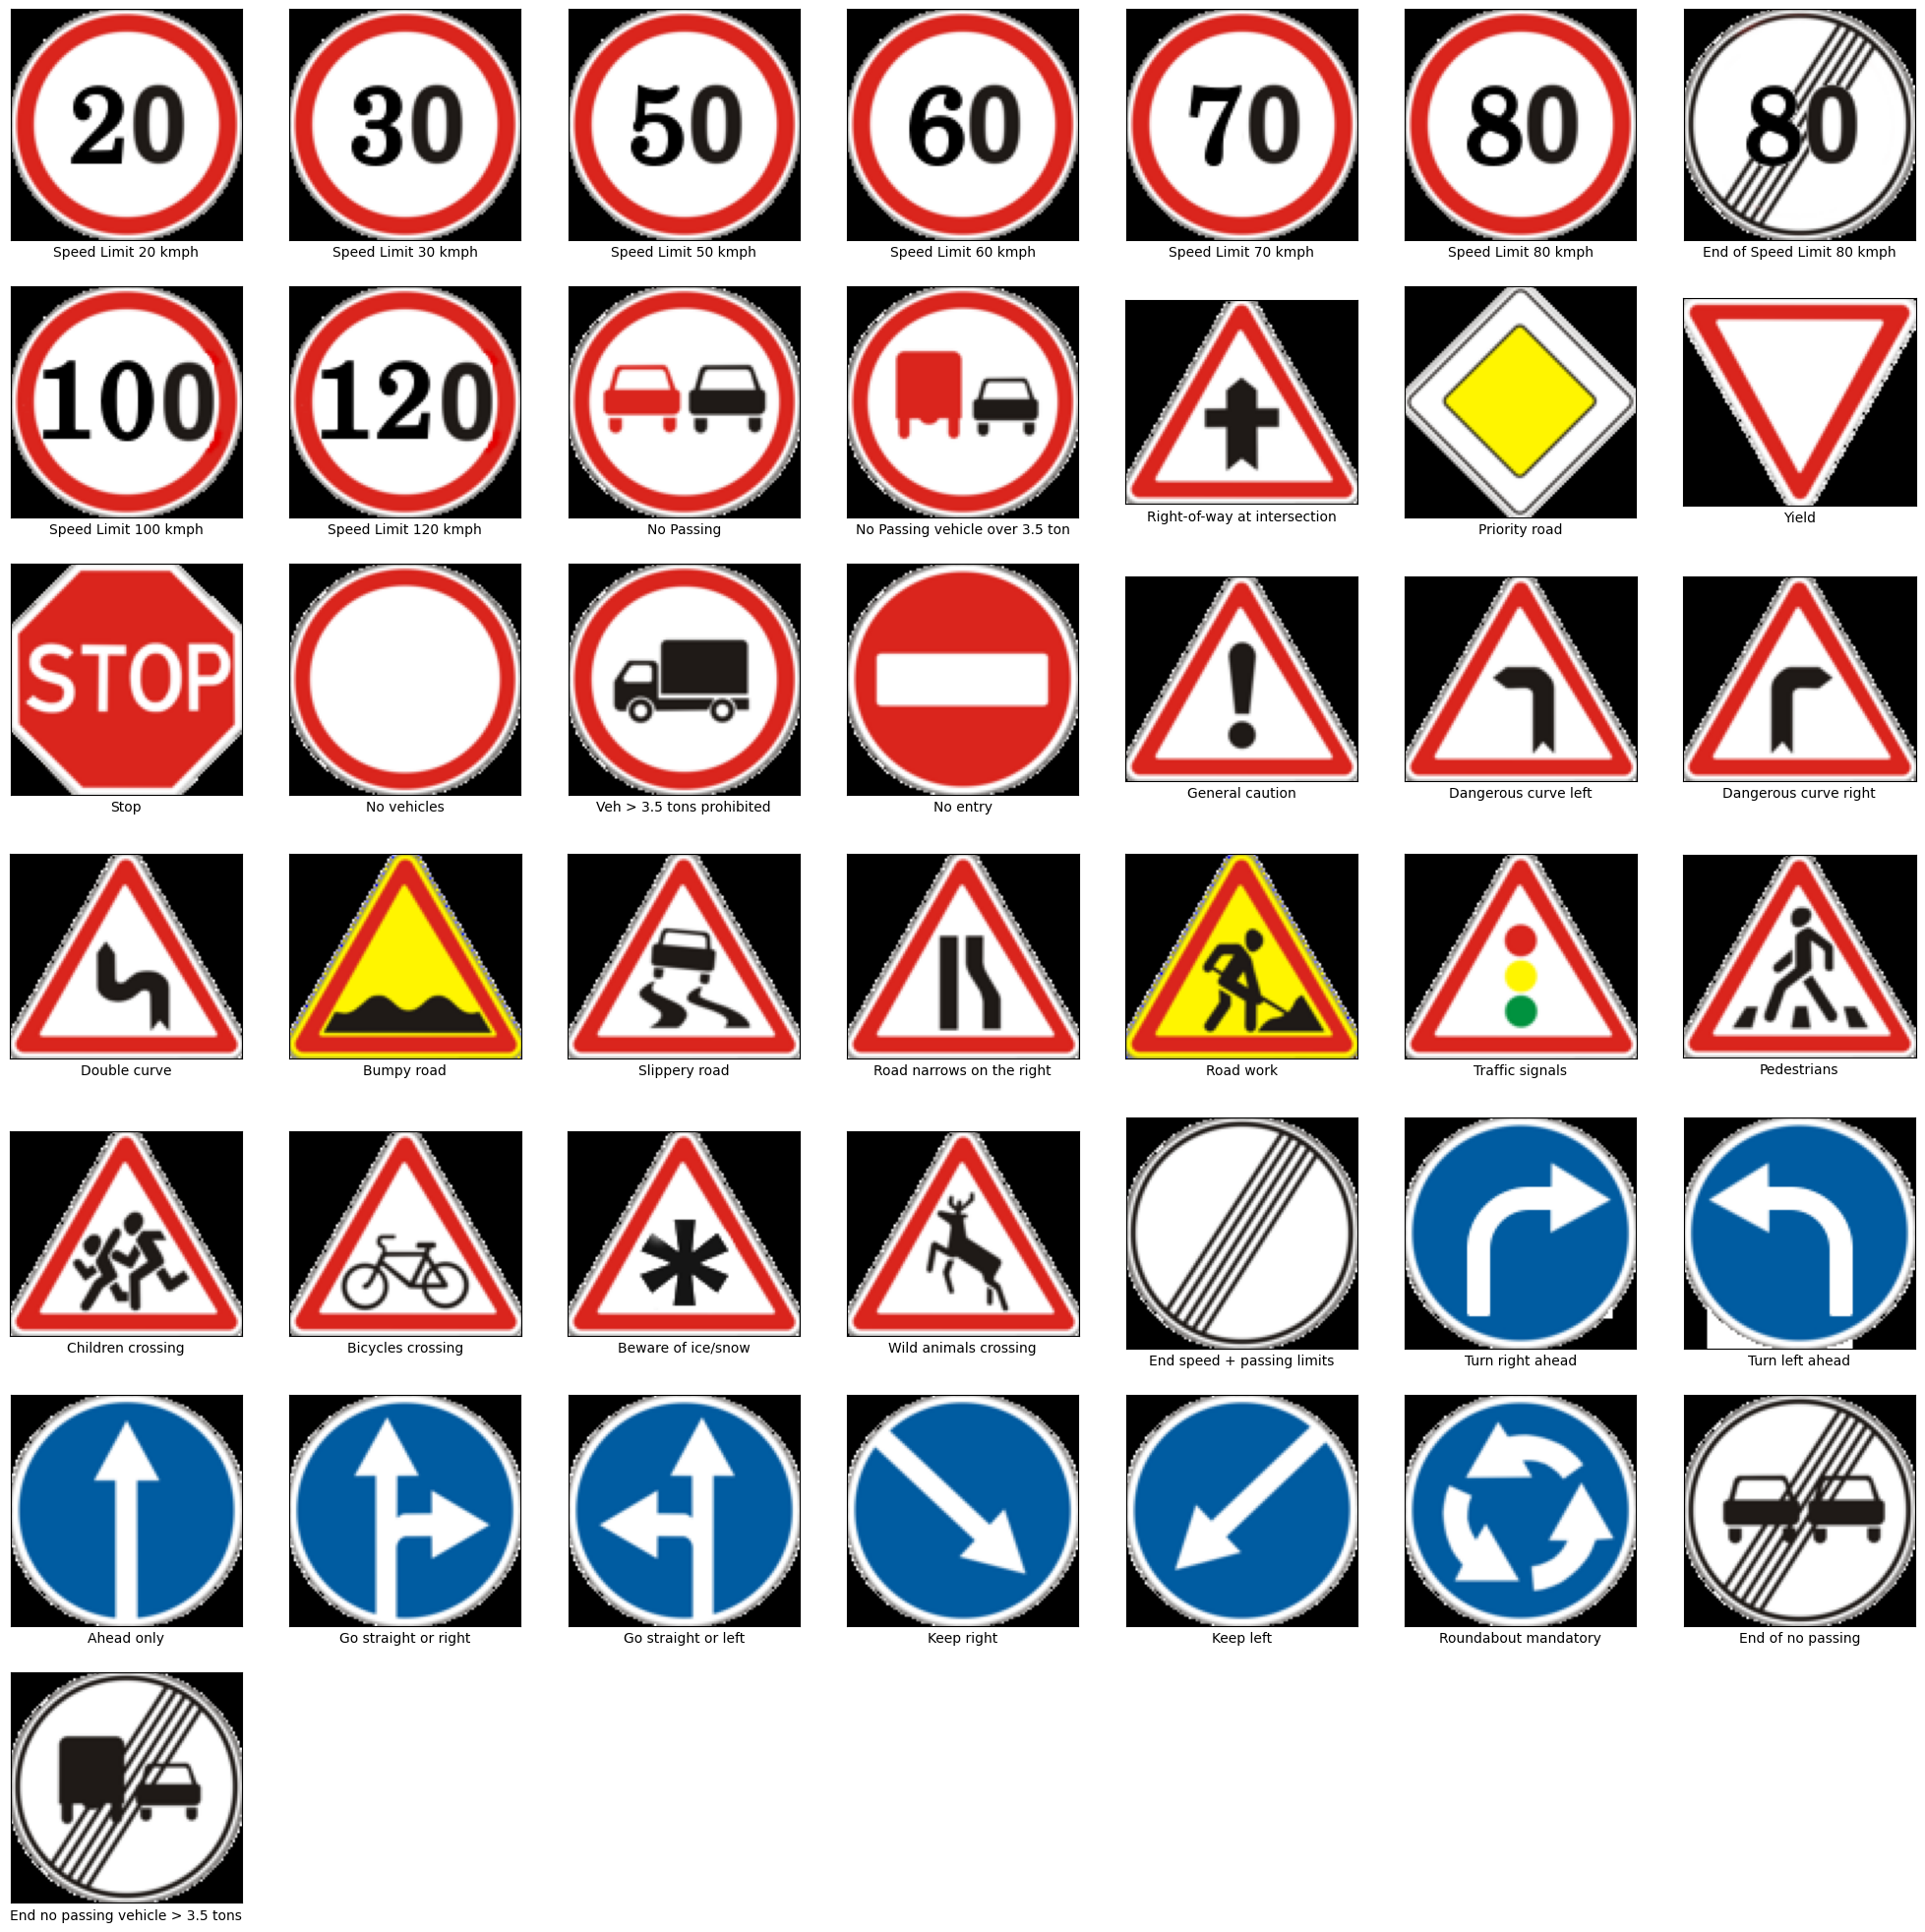

In [ ]:
sortFunction = lambda x: int(os.path.basename(x)[:-4])
plt.figure(figsize = (25, 25))
for i, imagename in enumerate(sorted(glob.glob(data_path + 'Meta/' + '*.*'), key = sortFunction)):
    plt.subplot(7, 7, i + 1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(class_dict[i])
    image = cv2.imread(imagename)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:
# Checking Value counts for ShapeId
shape_dict = {0: 'Triangle', 1: 'Circle', 2: 'Diamond', 3: 'Hexagon', 4: 'Inverse Triangle'}

shape_counts = df_meta.ShapeId.value_counts().sort_index()

for shape_id, count in shape_counts.items():
    shape_name = shape_dict[int(shape_id)]
    print(f"{int(shape_id)}: {shape_name} -> {int(count)}")

0: Triangle -> 15
1: Circle -> 25
2: Diamond -> 1
3: Hexagon -> 1
4: Inverse Triangle -> 1


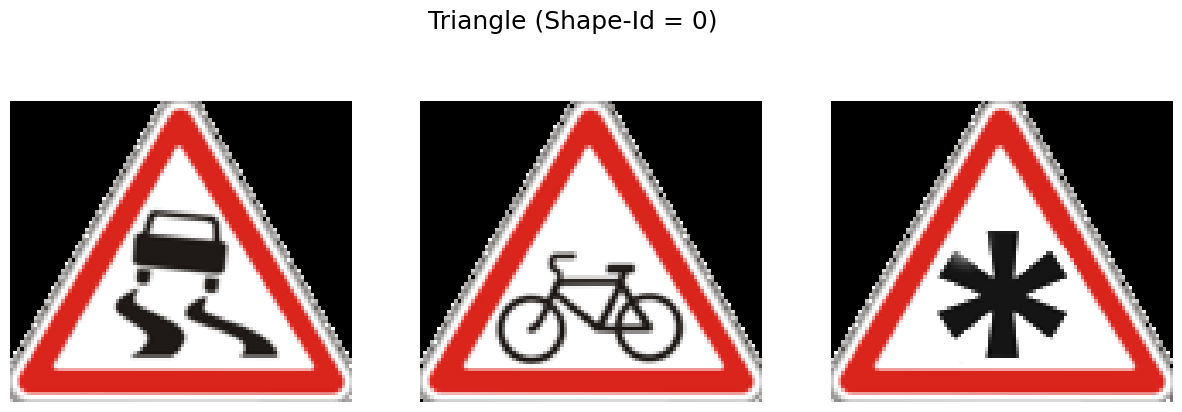

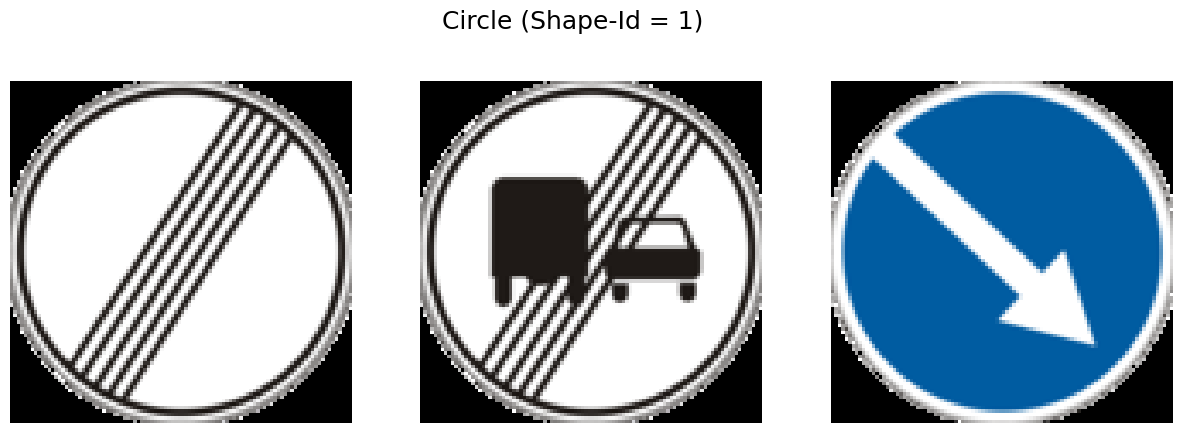

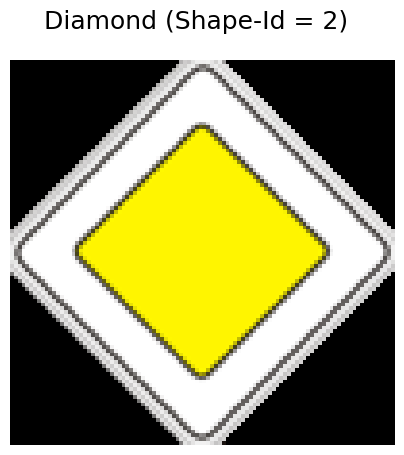

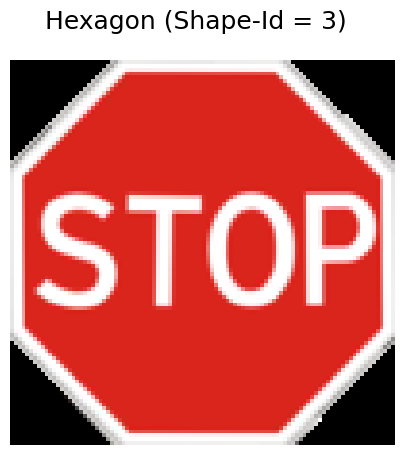

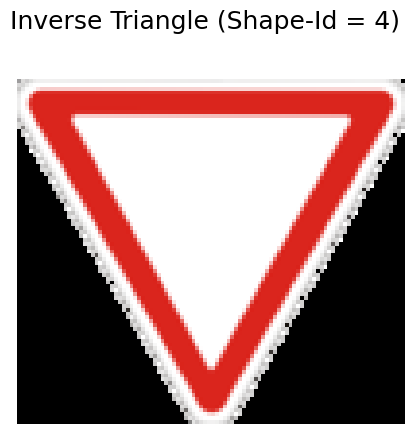

<Figure size 0x500 with 0 Axes>

In [ ]:
def visualize_shape(shape_id, n_images=1):
    subset = df_meta[df_meta.ShapeId == shape_id]
    filenames = subset.sample(min(n_images, len(subset))).Path.values

    images = [cv2.imread(os.path.join(data_path, filename)) for filename in filenames]

    plt.figure(figsize=(5 * len(images), 5))
    plt.suptitle(f"{shape_dict.get(shape_id, 'Unknown')} (Shape-Id = {shape_id})", fontsize=18)

    for i, img in enumerate(images):
        plt.subplot(1, len(images), i + 1)
        plt.axis('off')
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()

for shape_id in range(6):
    visualize_shape(shape_id, n_images=3 if shape_id in [0, 1] else 1)

In [ ]:
# Checking Value counts for ColorId
color_dict = {0: 'Red', 1: 'Blue', 2: 'Yellow', 3: 'White'}
color_counts = df_meta.ColorId.value_counts().sort_index()

for color_id, count in color_counts.items():
    color_name = color_dict[int(color_id)]
    print(f"{int(color_id)}: {color_name} -> {int(count)}")

0: Red -> 30
1: Blue -> 8
2: Yellow -> 1
3: White -> 4


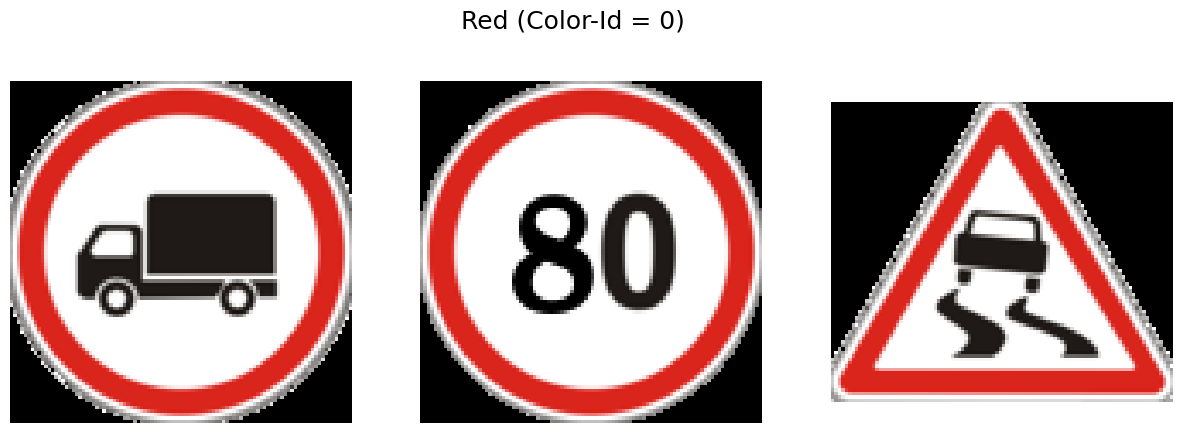

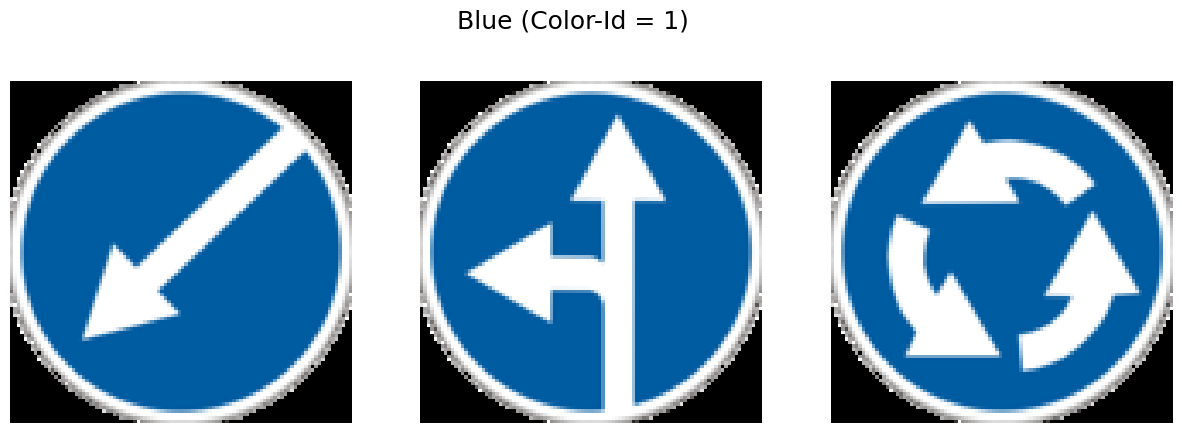

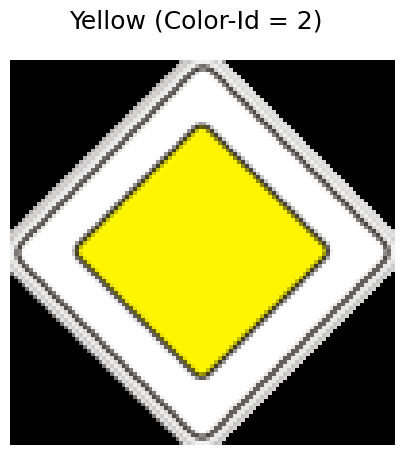

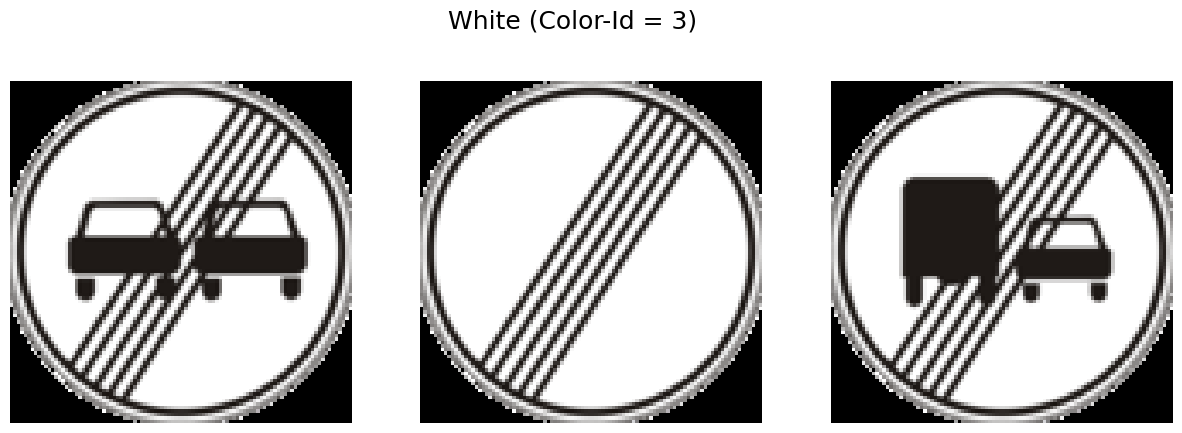

In [ ]:
def visualize_color(color_id, n_images=1):
    subset = df_meta[df_meta.ColorId == color_id]
    filenames = subset.sample(min(n_images, len(subset))).Path.values

    images = [cv2.imread(os.path.join(data_path, filename)) for filename in filenames]

    plt.figure(figsize=(5 * len(images), 5))
    plt.suptitle(f"{color_dict.get(color_id, 'Unknown')} (Color-Id = {color_id})", fontsize=18)

    for i, img in enumerate(images):
        plt.subplot(1, len(images), i + 1)
        plt.axis('off')
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()

for color_id in range(4):
    visualize_color(color_id, n_images=3 if color_id in [0, 1,3] else 1)

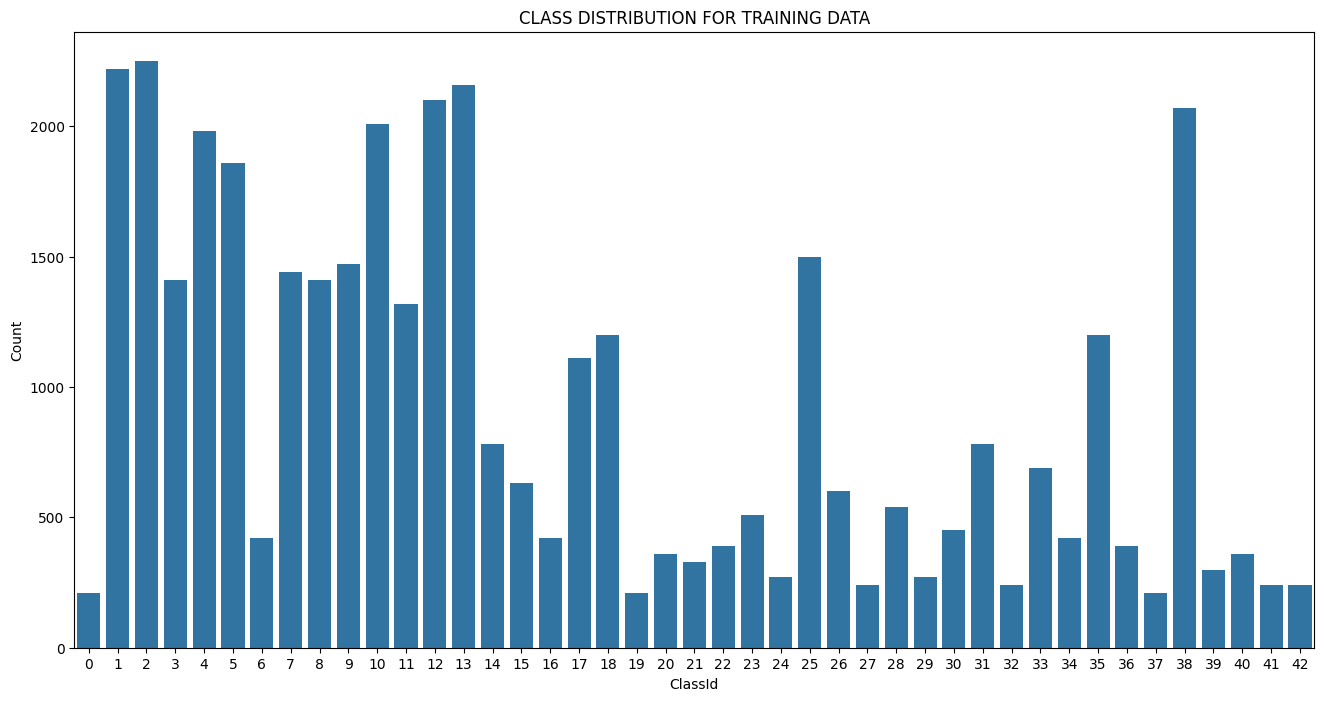

In [ ]:
plt.figure(figsize=(16, 8))
sns.countplot(x='ClassId', data=df_train)
plt.title('CLASS DISTRIBUTION FOR TRAINING DATA')
plt.xlabel('ClassId')
plt.ylabel('Count')
plt.show()

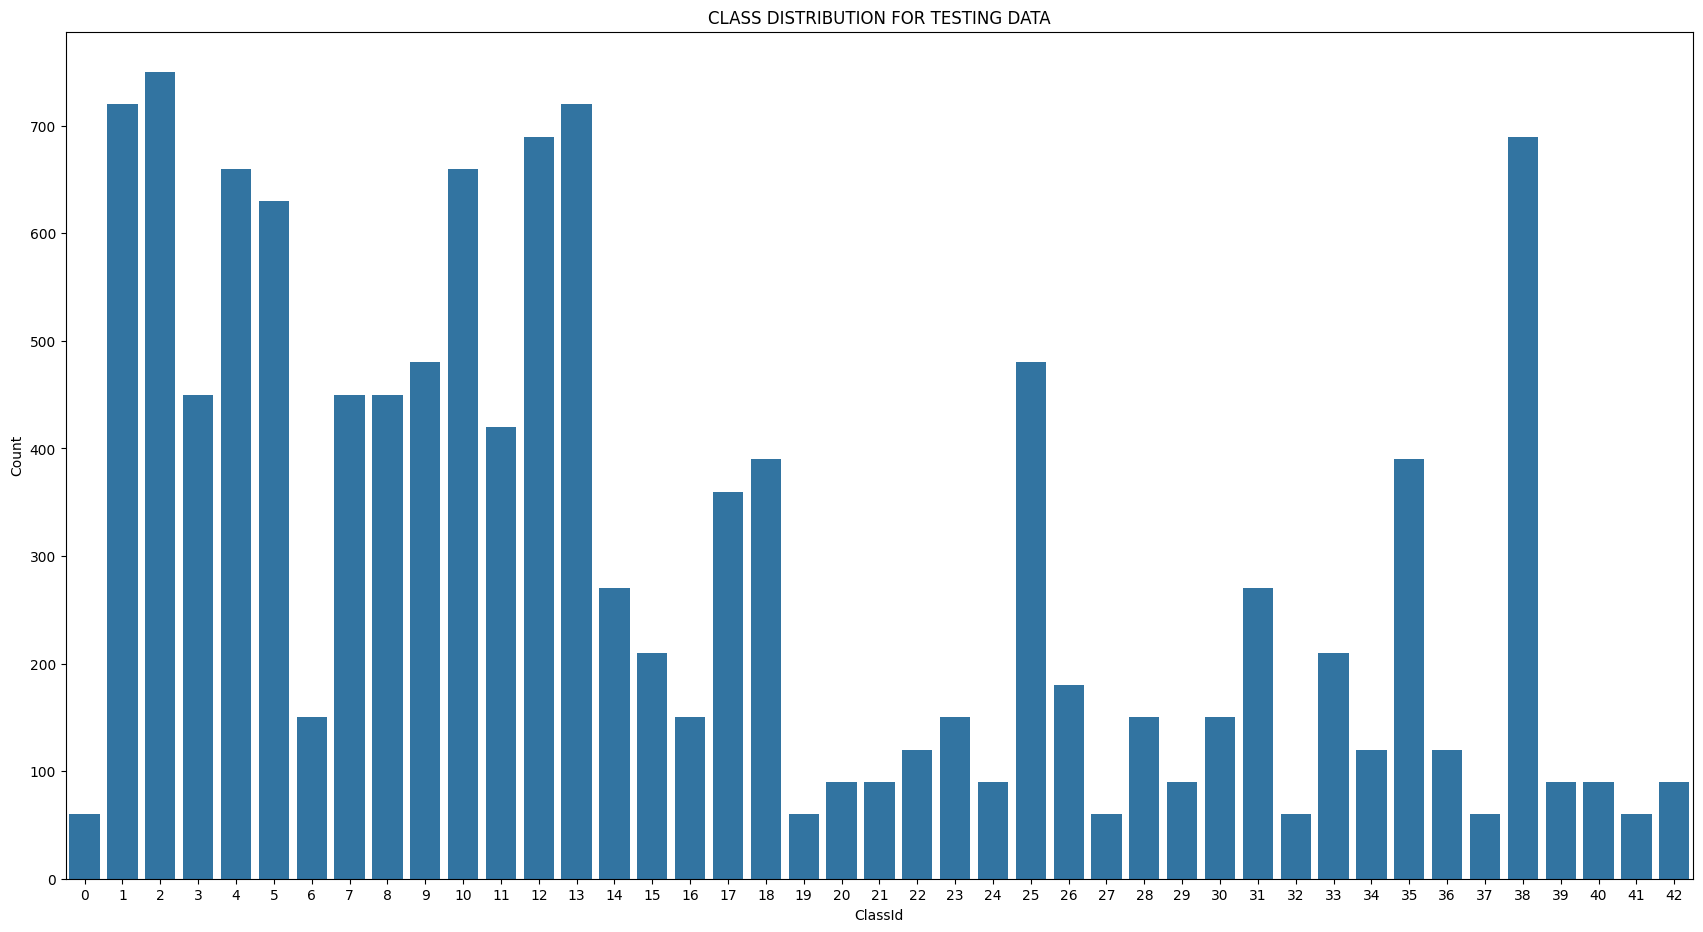

In [ ]:
plt.figure(figsize=(21, 11))
sns.countplot(x='ClassId', data=df_test)
plt.title('CLASS DISTRIBUTION FOR TESTING DATA')
plt.xlabel('ClassId')
plt.ylabel('Count')
plt.show()

In [ ]:
df_balance = pd.DataFrame()
df_balance['labels'] = list(range(43))
df_balance['train'] = train_dict.values()
df_balance['test'] = test_dict.values()
df_balance['total'] = df_balance['train'] + df_balance['test']
df_balance['train_ratio'] = df_balance['train']/df_balance['total']
df_balance['test_ratio'] = df_balance['test']/df_balance['total']

In [ ]:
df_balance.head(10)

,labels,train,test,total,train_ratio,test_ratio
0,0,210,60,270,0.777778,0.222222
1,1,2220,720,2940,0.755102,0.244898
2,2,2250,750,3000,0.750000,0.250000
3,3,1410,450,1860,0.758065,0.241935
4,4,1980,660,2640,0.750000,0.250000
5,5,1860,630,2490,0.746988,0.253012
6,6,420,150,570,0.736842,0.263158
7,7,1440,450,1890,0.761905,0.238095
8,8,1410,450,1860,0.758065,0.241935
9,9,1470,480,1950,0.753846,0.246154


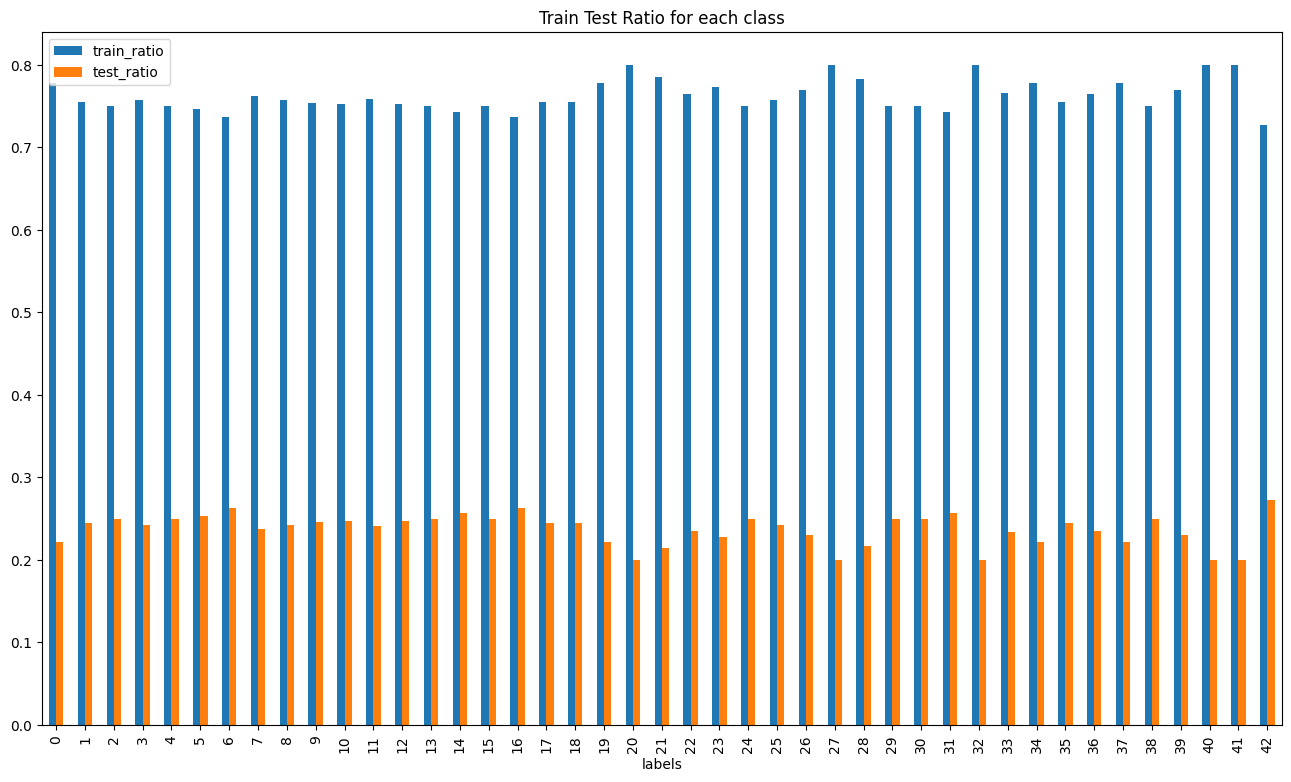

In [ ]:
df_balance.plot(x = 'labels', y = ['train_ratio', 'test_ratio'], kind = 'bar', figsize = (16, 9), title = "Train Test Ratio for each class")
plt.show()

In [ ]:
# Merging df_train with df_meta on 'ClassId' to get 'ColorId' and 'ShapeId' in df_train
df_train = df_train.merge(df_meta[['ClassId', 'ColorId']], on='ClassId', how='left')
df_train = df_train.merge(df_meta[['ClassId', 'ShapeId']], on='ClassId', how='left')

# Visualizing random samples
df_train.sample(5)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,ColorId,ShapeId
13583,53,50,6,5,48,45,9,Train/9/00009_00000_00023.png,0,1
24575,43,45,6,5,37,39,17,Train/17/00017_00004_00005.png,0,1
2287,33,33,6,6,28,28,1,Train/1/00001_00057_00007.png,0,1
35903,54,54,5,5,48,49,37,Train/37/00037_00003_00024.png,1,1
9838,108,113,10,10,99,104,5,Train/5/00005_00046_00028.png,0,1


In [ ]:
# Merging df_test with df_meta on 'ClassId' to get 'ColorId' and 'ShapeId' in df_test
df_test = df_test.merge(df_meta[['ClassId', 'ColorId']], on='ClassId', how='left')
df_test = df_test.merge(df_meta[['ClassId', 'ShapeId']], on='ClassId', how='left')

# Visualizing random samples
df_test.sample(5)

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,ColorId,ShapeId
5517,27,27,5,5,22,22,17,Test/05517.png,0,1
6686,28,28,5,5,23,23,9,Test/06686.png,0,1
4951,41,42,5,6,36,37,40,Test/04951.png,1,1
2124,68,61,6,6,62,56,11,Test/02124.png,0,0
3879,38,42,5,6,33,36,7,Test/03879.png,0,1


## Exploratory Data Analysis (EDA)

The notebook performs several EDA steps:

1. Displays metadata samples and structure.
2. Checks dataset shapes and descriptive statistics.
3. Checks duplicate records.
4. Finds minimum and maximum class IDs.
5. Counts images per class.
6. Visualizes traffic-sign class distributions.
7. Maps class IDs to traffic-sign descriptions.
8. Inspects sign shapes such as triangle, circle, diamond, hexagon, and inverse triangle.
9. Inspects sign colors such as red, blue, yellow, and white.
10. Examines train/test ratios for each class.

These steps help identify the structure and distribution of the available data before model training.

##  Image Preprocessing

The images used for CNN training are processed as follows:

### Step 1 — Image Loading
Images are loaded from the training class folders.

### Step 2 — Resizing
Every training and test image is resized to **32 × 32 pixels**.

### Step 3 — Array Conversion
Images are converted into NumPy arrays.

### Step 4 — Normalization
Pixel values are divided by **255**, converting the approximate pixel range from 0–255 to 0–1.

### Step 5 — Label Encoding
The 43 class labels are converted to one-hot encoded vectors for categorical classification.

### Step 6 — Train/Validation Split
The loaded training data is split using a **75% training / 25% validation** split with stratification and `random_state=42`.

The resulting arrays shown in the notebook are:
- Training: **1,822 images**
- Validation: **608 images**
- Image size: **32 × 32 × 3**
- Label dimension: **43 classes**

In [ ]:
train_data = []
train_labels = []
train_folders = os.listdir(train_path)
for folders in tqdm.tqdm(train_folders):
    imagefiles = os.listdir(train_path + folders)
    for imagefile in imagefiles:
        path = os.path.join(train_path, folders, imagefile)
        image = Image.open(path)
        image = image.resize((32, 32))
        image = np.array(image)
        train_data.append(image)
        train_labels.append(int(folders))

100%|██████████| 2/2 [00:39<00:00, 19.80s/it]


In [ ]:
train_data = np.array(train_data) / 255.
train_labels = np.array(train_labels)

In [ ]:
len(df_train), len(train_data), len(train_labels)

(39209, 2430, 2430)

In [ ]:
print("There are {} images in train dataset".format(len(train_data)))
print("Each image has a dimension of : {}".format(train_data[0].shape))

There are 2430 images in train dataset
Each image has a dimension of : (32, 32, 3)


In [ ]:
test_data = []
test_labels = df_test.ClassId.tolist()
test_filenames = (data_path + df_test.Path).tolist()

for test_filename in tqdm.tqdm(test_filenames):
    # cv2.imread reads as BGR by default
    image = cv2.imread(test_filename)
    # Resize to 32x32
    image = cv2.resize(image, (32, 32))
    # Convert BGR to RGB (if your model expects RGB)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    test_data.append(image)

100%|██████████| 12630/12630 [1:00:50<00:00,  3.46it/s]


In [ ]:
X_test = np.array(test_data) / 255.
y_test = np.array(test_labels)

In [ ]:
y_test= to_categorical(y_test)
y_test


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
len(df_test), len(X_test), len(test_labels)


(12630, 12630, 12630)

In [ ]:
print("There are {} images in test dataset".format(len(X_test)))
print("Each image has a dimension of : {}".format(X_test[0].shape))

There are 12630 images in test dataset
Each image has a dimension of : (32, 32, 3)


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(train_data, train_labels, test_size = 0.25, stratify = train_labels, random_state = 42)
train_unique, y_train_count = np.unique(y_train, return_counts = True)
val_unique, y_val_count = np.unique(y_val, return_counts = True)
y_train, y_val = to_categorical(y_train, num_classes), to_categorical(y_val, num_classes)
print("X_train : {}".format(X_train.shape))
print("y_train : {}".format(y_train.shape))
print("X_val   : {}".format(X_val.shape))
print("y_val   : {}".format(y_val.shape))

X_train : (1822, 32, 32, 3)
y_train : (1822, 43)
X_val   : (608, 32, 32, 3)
y_val   : (608, 43)


In [ ]:
test_unique, y_test_count = np.unique(y_test, return_counts = True)

##  CNN Model Architecture

The classifier is implemented using Keras `Sequential`.

### Architecture
1. Convolution layer: 32 filters, 3×3 kernel, ReLU
2. Batch normalization
3. Second convolution layer: 32 filters
4. Max pooling
5. Dropout: 0.25
6. Convolution layer: 64 filters
7. Batch normalization
8. Second 64-filter convolution layer
9. Max pooling
10. Dropout: 0.25
11. Convolution layer: 128 filters
12. Batch normalization
13. Max pooling
14. Dropout: 0.30
15. Global Average Pooling
16. Dense layer: 128 neurons, ReLU
17. Dropout: 0.40
18. Output layer: 43 neurons with softmax

The softmax output represents the predicted probability distribution across the 43 traffic-sign classes.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=X_train.shape[1:]),
    BatchNormalization(),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.4),

    Dense(num_classes, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,379 (634.29 KB)

 Trainable params: 161,931 (632.54 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

datagen.fit(X_train)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [ ]:
import tensorflow as tf

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=[
        'accuracy',
        tf.keras.metrics.TopKCategoricalAccuracy(
            k=3,
            name='top_3_accuracy'
        ),
        tf.keras.metrics.TopKCategoricalAccuracy(
            k=5,
            name='top_5_accuracy'
        )
    ]
)

history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=True
)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.8518 - loss: 0.7142 - top_3_accuracy: 0.9347 - top_5_accuracy: 0.9490 - val_accuracy: 0.0362 - val_loss: 3.7326 - val_top_3_accuracy: 0.0855 - val_top_5_accuracy: 0.1414 - learning_rate: 0.0010
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 136ms/step - accuracy: 0.8974 - loss: 0.2923 - top_3_accuracy: 0.9989 - top_5_accuracy: 1.0000 - val_accuracy: 0.0872 - val_loss: 2.6729 - val_top_3_accuracy: 0.7681 - val_top_5_accuracy: 0.7911 - learning_rate: 0.0010
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 171ms/step - accuracy: 0.9210 - loss: 0.2188 - top_3_accuracy: 1.0000 - top_5_accuracy: 1.0000 - val_accuracy: 0.0872 - val_loss: 2.7715 - val_top_3_accuracy: 0.7747 - val_top_5_accuracy: 0.7845 - learning_rate: 0.0010
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 133ms/step - accuracy: 0.9599 - loss: 0.1136 - top_3_accuracy: 1.0000 - top_5_accuracy: 1.0000 - val_accuracy: 0.0872 - val_loss: 2.9461 - val_top_3_accuracy: 0.6546 - val_top_5

##  Data Augmentation

The training pipeline uses `ImageDataGenerator` with:

- Rotation range: **10°**
- Width shift: **0.1**
- Height shift: **0.1**
- Zoom range: **0.1**

The purpose is to expose the CNN to small variations in image orientation, position, and scale and to reduce dependence on exact image positioning.

##  Training Strategy

The model is compiled with:

- **Loss:** categorical cross-entropy
- **Optimizer:** Adam
- **Metrics:** accuracy, top-3 accuracy, and top-5 accuracy
- **Maximum epochs:** 30
- **Batch size:** 32

Two callbacks are used:

### EarlyStopping
Monitors validation loss, waits for 5 epochs without improvement, and restores the best weights.

### ReduceLROnPlateau
Monitors validation loss and reduces the learning rate by a factor of 0.5 after 2 stagnant epochs, with a minimum learning rate of 1e-6.

## Training Performance

The notebook records training and validation accuracy/loss curves. These plots are useful for examining whether the model is learning consistently and whether the validation behavior differs substantially from training behavior.

The stored training log shows that training accuracy became very high while validation accuracy remained much lower for substantial portions of training. This indicates a strong train/validation generalization gap in the current run and should be considered when interpreting the final test result.

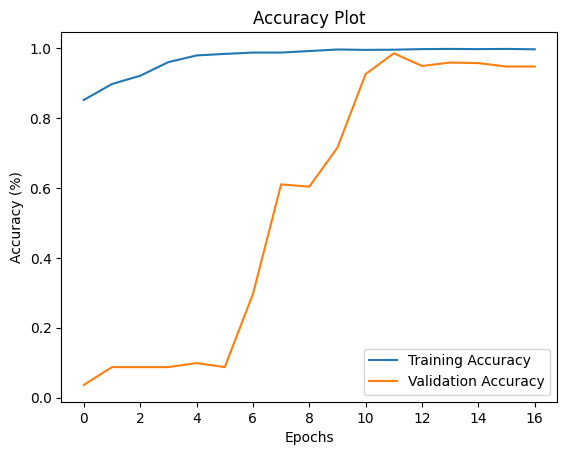

In [ ]:
plt.figure()
plt.plot(history.history['accuracy'], label = "Training Accuracy")
plt.plot(history.history['val_accuracy'], label = "Validation Accuracy")
plt.title("Accuracy Plot")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

loss function

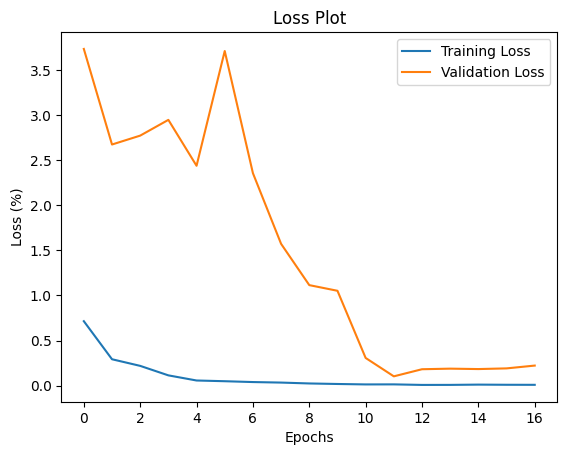

In [ ]:
plt.figure()
plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation Loss")
plt.title("Loss Plot")
plt.xlabel("Epochs")
plt.ylabel("Loss (%)")
plt.legend()
plt.show()

## Model Evaluation

The notebook evaluates the model on the 12,630-image test set using:

- Test loss
- Test accuracy
- Top-3 accuracy
- Top-5 accuracy
- Predicted class labels
- Prediction confidence
- Confusion matrix
- Classification report

### Recorded test metrics in this notebook run

| Metric | Value |
|---|---:|
| Test loss | 6.9884 |
| Test accuracy | 0.0616 |
| Test top-3 accuracy | 0.1087 |
| Test top-5 accuracy | 0.1591 |

These values describe this particular notebook run and should not be presented as a general performance claim for all versions of the project.

In [ ]:
print("Loss of the model is - " , model.evaluate(X_test,y_test)[0])
print("\n")
print("Accuracy of the model is - " , model.evaluate(X_test,y_test)[1])

395/395 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.0616 - loss: 6.9884 - top_3_accuracy: 0.1087 - top_5_accuracy: 0.1591
Loss of the model is -  6.988381862640381


395/395 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.0616 - loss: 6.9884 - top_3_accuracy: 0.1087 - top_5_accuracy: 0.1591
Accuracy of the model is -  0.06159936636686325


In [ ]:
# Get prediction probabilities for each class
predictions = model.predict(X_test)

# Convert probabilities to class labels
predicted_classes = predictions.argmax(axis=1)

# Get confidence score
confidence = predictions.max(axis=1)

print("Predicted Classes:")
print(predicted_classes)

print("\nConfidence Scores:")
for i in range(10):
    print(
        "Predicted:",
        class_dict[predicted_classes[i]],
        "| Confidence:",
        f"{confidence[i] * 100:.2f}%"
    )

395/395 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step
Predicted Classes:
[0 1 1 ... 1 1 1]

Confidence Scores:
Predicted: Speed Limit 20 kmph | Confidence: 97.34%
Predicted: Speed Limit 30 kmph | Confidence: 100.00%
Predicted: Speed Limit 30 kmph | Confidence: 90.90%
Predicted: Speed Limit 20 kmph | Confidence: 99.95%
Predicted: Speed Limit 20 kmph | Confidence: 51.22%
Predicted: Speed Limit 30 kmph | Confidence: 98.63%
Predicted: Speed Limit 30 kmph | Confidence: 64.77%
Predicted: Speed Limit 30 kmph | Confidence: 73.91%
Predicted: Speed Limit 20 kmph | Confidence: 99.38%
Predicted: Speed Limit 30 kmph | Confidence: 46.54%


In [ ]:
num_classes = len(np.unique(y_test))
y_true = y_test

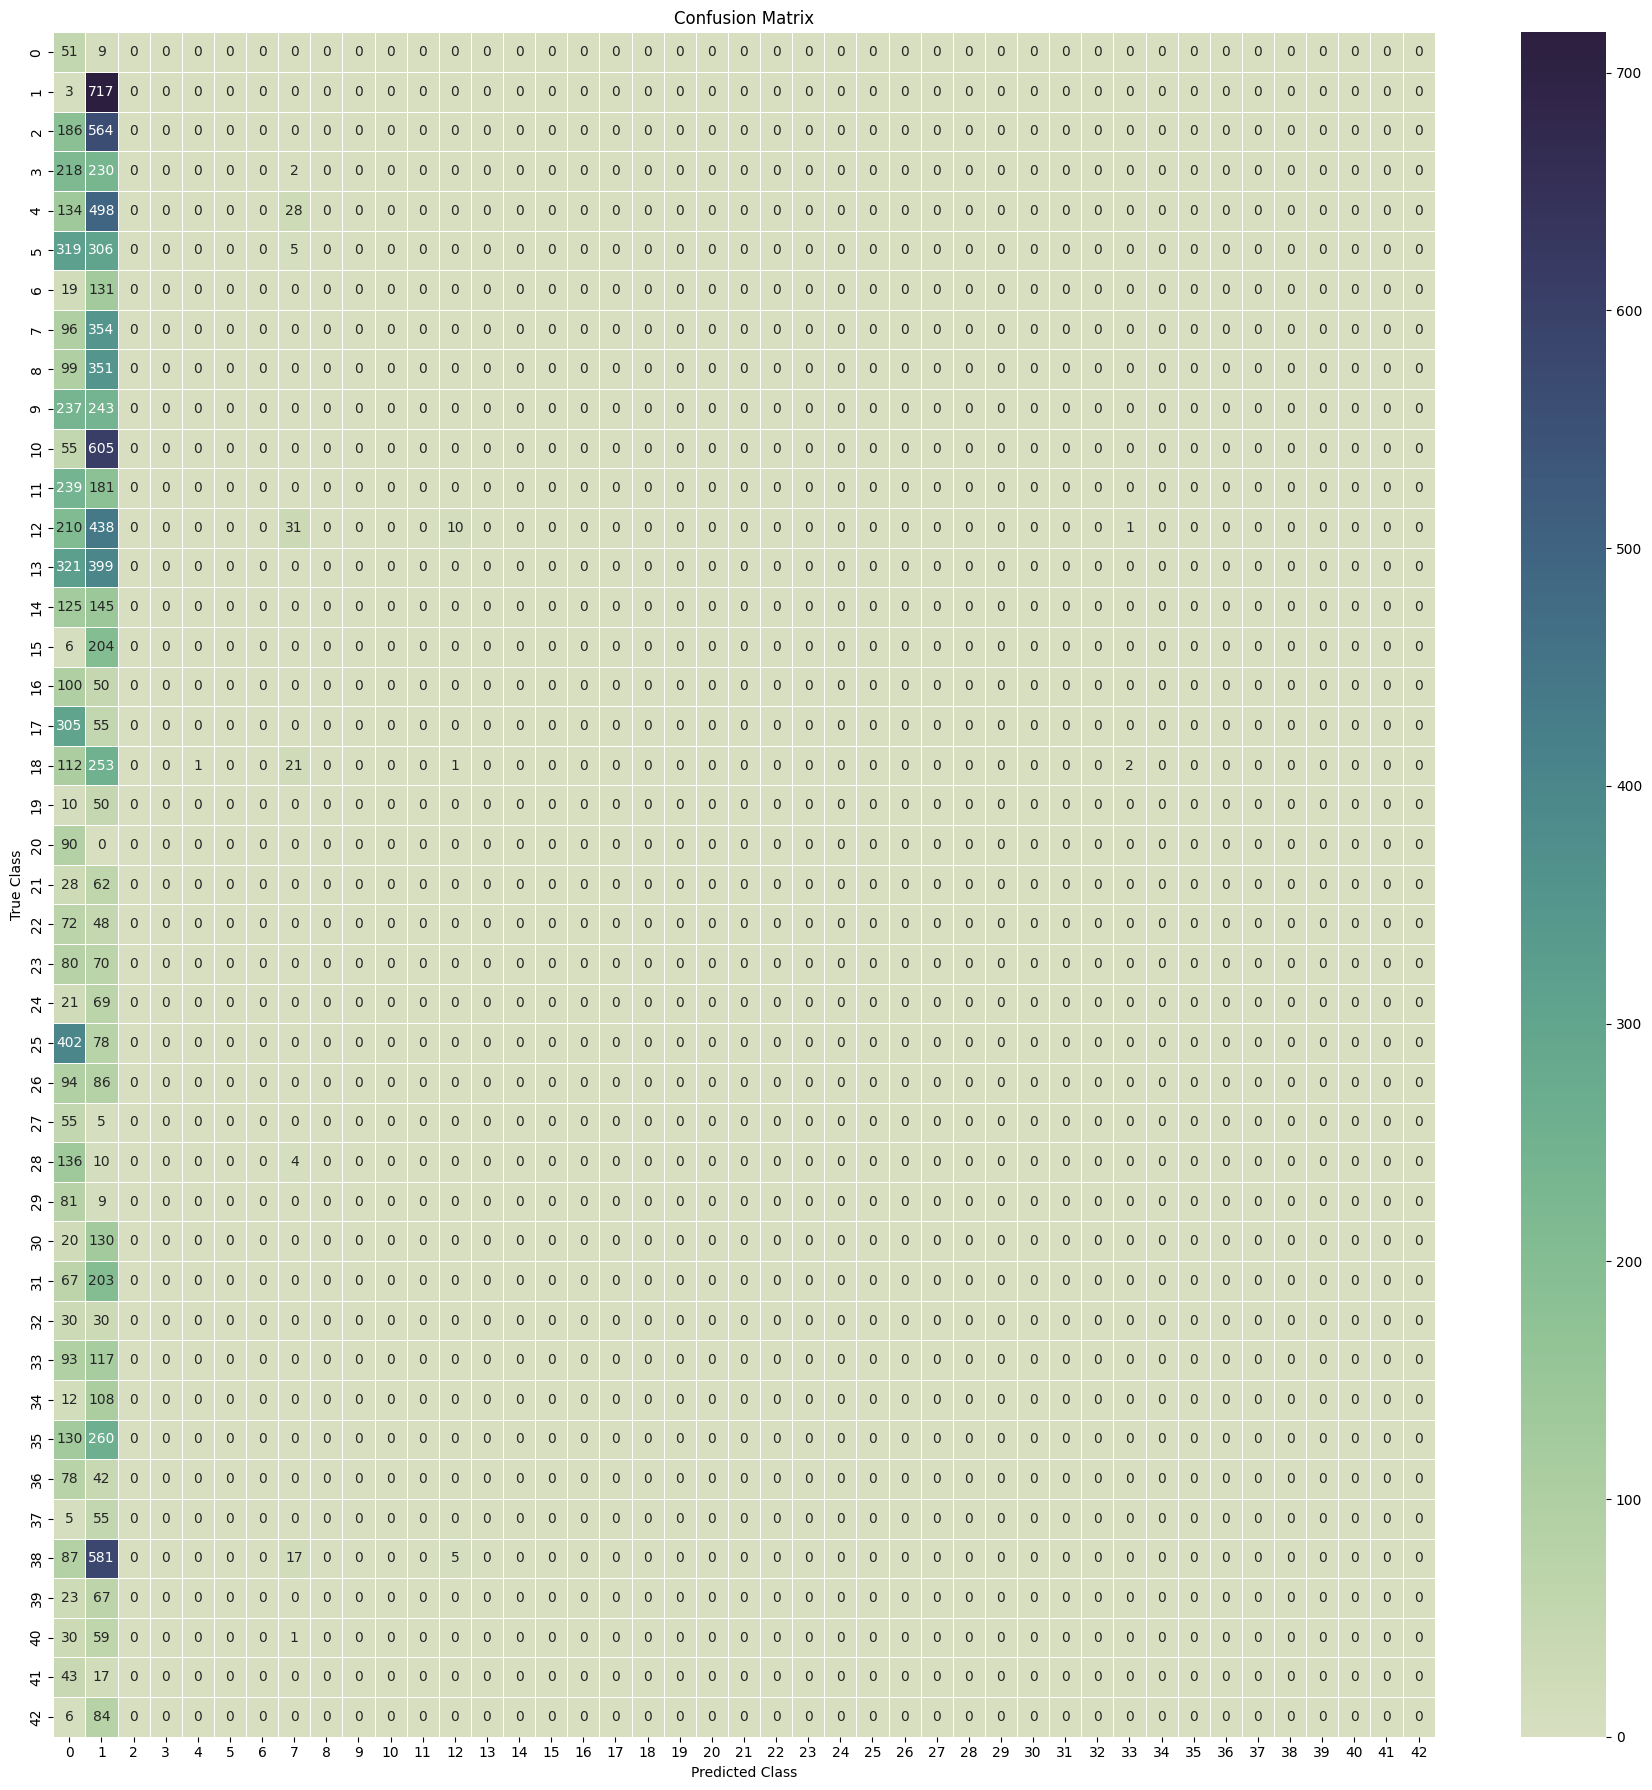

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Number of classes
num_classes = y_test.shape[1]

# Convert one-hot encoded true labels to class numbers
y_test_labels = np.argmax(y_test, axis=1)

# Convert predictions to class numbers
y_pred = np.asarray(predicted_classes).flatten()

# Create confusion matrix
cm = confusion_matrix(
    y_test_labels,
    y_pred,
    labels=np.arange(num_classes)
)

# Convert confusion matrix to DataFrame
df_cm = pd.DataFrame(
    cm,
    index=np.arange(num_classes),
    columns=np.arange(num_classes)
)

plt.figure(figsize=(18 , 18))

cmap = sns.cubehelix_palette(
    start=0.5,
    rot=-0.75,
    as_cmap=True
)

sns.heatmap(
    df_cm,
    annot=True,
    fmt="d",
    cmap=cmap,
    vmin=0,
    vmax=cm.max(),
    linewidths=0.5,
    xticklabels=np.arange(num_classes),
    yticklabels=np.arange(num_classes),
    cbar=True
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# True class labels
y_true = y_test_labels

# Predicted class labels
y_pred = np.asarray(predicted_classes).flatten()

# Classification report
print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    digits=4
))

Classification Report:

              precision    recall  f1-score   support

           0     0.0113    0.8500    0.0222        60
           1     0.0899    0.9958    0.1650       720
           2     0.0000    0.0000    0.0000       750
           3     0.0000    0.0000    0.0000       450
           4     0.0000    0.0000    0.0000       660
           5     0.0000    0.0000    0.0000       630
           6     0.0000    0.0000    0.0000       150
           7     0.0000    0.0000    0.0000       450
           8     0.0000    0.0000    0.0000       450
           9     0.0000    0.0000    0.0000       480
          10     0.0000    0.0000    0.0000       660
          11     0.0000    0.0000    0.0000       420
          12     0.6250    0.0145    0.0283       690
          13     0.0000    0.0000    0.0000       720
          14     0.0000    0.0000    0.0000       270
          15     0.0000    0.0000    0.0000       210
          16     0.0000    0.0000    0.0000       150
   

In [ ]:
# Keep original test labels
y_test_labels = np.array(y_test)

# One-hot encoded labels for model evaluation
y_test = to_categorical(y_test_labels, num_classes=num_classes)

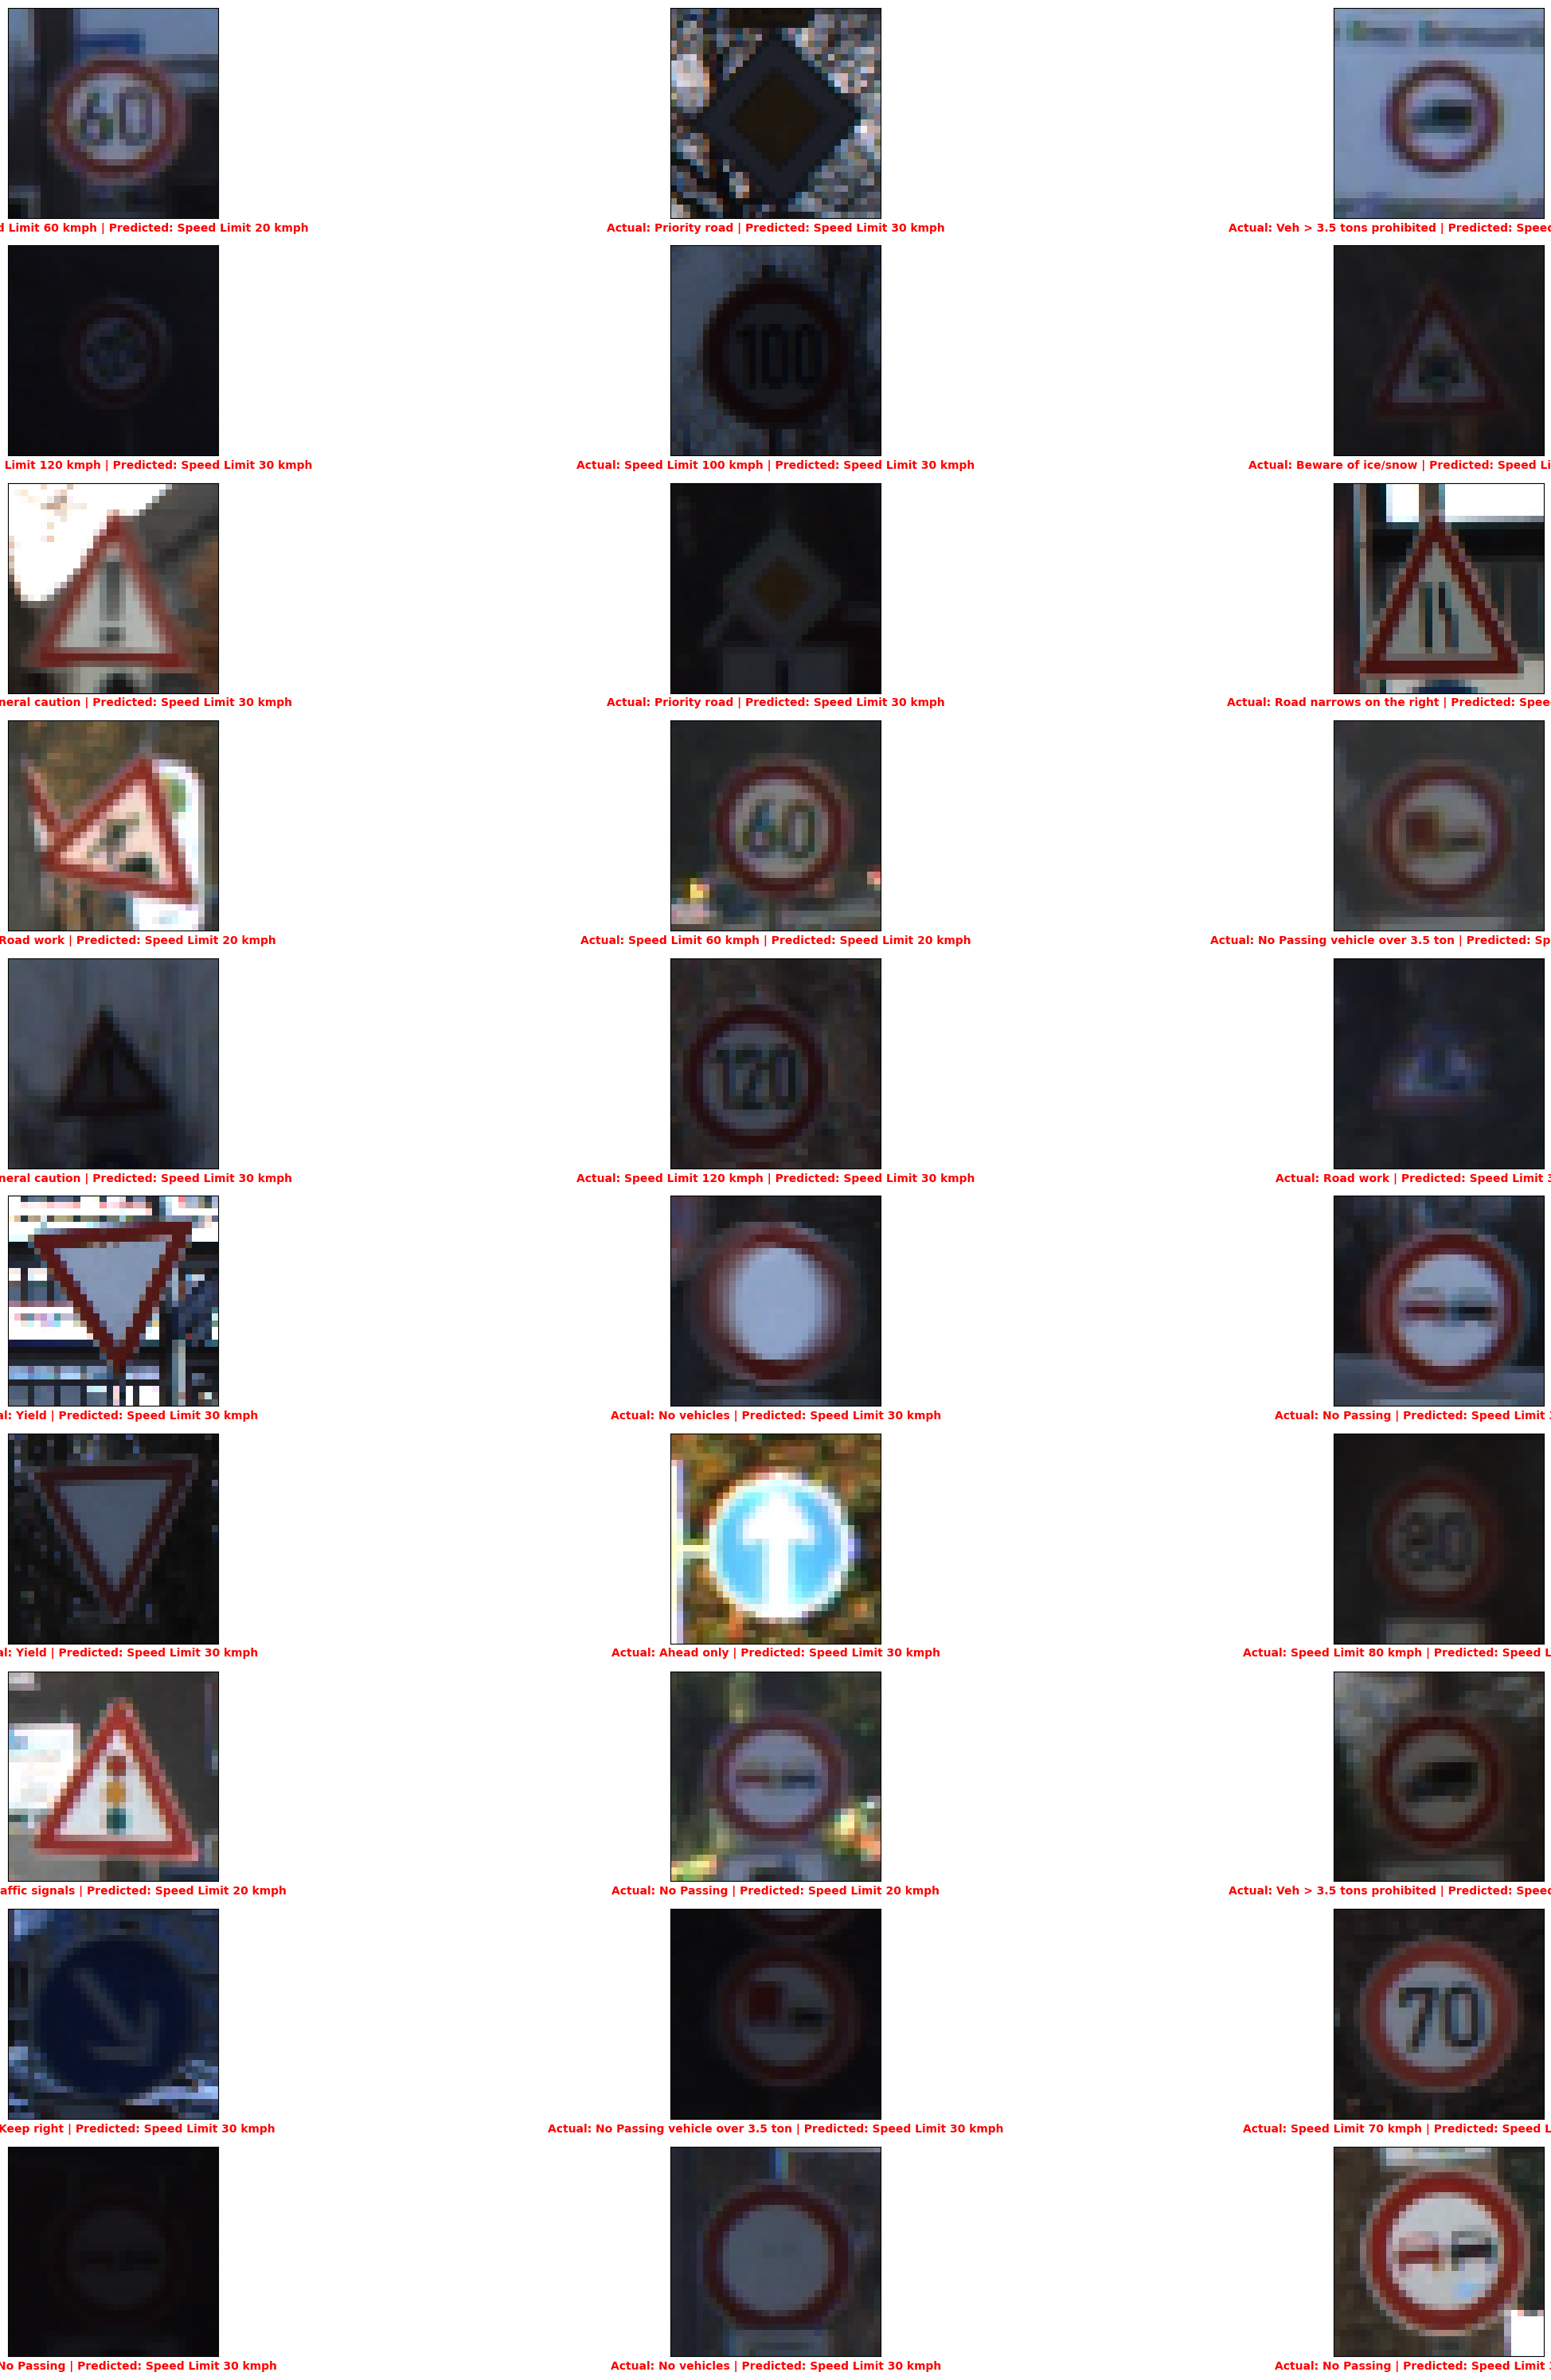

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure predictions are class numbers
y_pred = np.asarray(predicted_classes)

# If predictions are one-hot/probabilities, convert to class numbers
if y_pred.ndim > 1:
    y_pred = np.argmax(y_pred, axis=1)

# Make sure ground-truth labels are class numbers
y_true = np.asarray(y_test_labels)

if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

plt.figure(figsize=(30, 30))

start_index = 36

for i in range(30):
    plt.subplot(10, 3, i + 1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    index = start_index + i

    prediction = int(y_pred[index])
    ground_truth = int(y_true[index])

    col = 'g' if prediction == ground_truth else 'r'

    plt.xlabel(
        'Actual: {} | Predicted: {}'.format(
            class_dict.get(ground_truth, ground_truth),
            class_dict.get(prediction, prediction)
        ),
        color=col,
        weight='bold'
    )

    plt.imshow(X_test[index])

plt.tight_layout()
plt.show()

## Results and Error Analysis

The classification report and confusion matrix provide class-wise error information.

For the recorded run, overall test accuracy is approximately **6.16%**. The classification report shows that performance is highly uneven across classes, with many classes having zero recall in this run. Therefore, the current model should be treated as an experimental implementation rather than a deployment-ready traffic-sign recognizer.

A major implementation issue visible in the notebook is the mismatch between the training CSV size (**39,209 records**) and the number of images actually loaded from the training folders (**2,430**). Since the CNN uses the folder-loaded arrays, this data-loading mismatch is an important area for correction before drawing conclusions about model quality.

##  Prediction and Confidence

For each test image, the model produces a probability for every class. The predicted class is selected using `argmax`, and the largest probability is reported as the confidence score.

The notebook also visualizes sample predictions and compares the actual and predicted class descriptions. Correct predictions are displayed differently from incorrect predictions to support qualitative error analysis.

## Model Saving

The trained model is saved as:

`traffic_sign_model.keras`

The notebook then demonstrates loading the saved Keras model back into memory. This makes the trained model reusable without retraining from the beginning.

In [ ]:
model.save("traffic_sign_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("traffic_sign_model.keras")
print("Model loaded successfully!")

Model loaded successfully!


#  Conclusion

This project demonstrates an end-to-end deep-learning workflow for traffic-sign image classification. The implementation covers dataset exploration, image preprocessing, class-label preparation, CNN design, data augmentation, training, validation, test evaluation, error analysis, and model persistence.

The current notebook successfully builds and saves a 43-class CNN model. However, the recorded test performance is low, with approximately **6.16% test accuracy**, and the classification report shows substantial class-wise errors. The results also reveal a data-loading inconsistency: the training CSV contains 39,209 records, but only 2,430 images are loaded from the training directories for CNN training.

Consequently, the most important conclusion from this version is that the complete pipeline is implemented, but the data-loading/training-data issue should be resolved and the model should be retrained before the system is considered reliable for traffic-sign recognition.

#  Future Scope

The following improvements can be considered in future versions:

1. **Correct the training-data loading pipeline** so that all intended training images are consistently used.
2. **Verify folder structure and CSV paths** before training.
3. **Use the complete and correctly labeled dataset** intended by the project.
4. **Apply stronger augmentation** where appropriate for lighting, rotation, translation, and scale variations.
5. **Experiment with transfer learning** using established image-classification architectures.
6. **Tune hyperparameters** such as learning rate, batch size, dropout, and number of epochs.
7. **Address class imbalance** using suitable sampling or class-weight strategies when required.
8. **Use additional evaluation metrics**, including macro/weighted F1-score and per-class recall.
9. **Perform systematic error analysis** on frequently confused traffic-sign classes.
10. **Create a real-time inference application** using a camera/video stream.
11. **Optimize the model for edge devices** if deployment on embedded hardware is required.
12. **Add confidence thresholds and an unknown/uncertain prediction mechanism** for safer real-world use.